In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path

In [6]:
# Comprobar directorio de trabajo
print("Directorio actual:", Path.cwd())

# Definir carpeta de datos
DATA_PATH = Path("../data/raw")

# Definir archivos
archivos = {
    2022: "Implantacion IA empresas (2022).csv",
    2023: "Implantacion IA empresas (2023).csv",
    2024: "Implantacion IA empresas (2024).csv",
    2025: "Implantacion IA empresas (2025).csv",
    2026: "Implantacion IA empresas (2026).csv"
}

# Comprobar que existen
for year, filename in archivos.items():
    ruta = DATA_PATH / filename
    print(year, "->", ruta.exists(), ruta)

Directorio actual: c:\Users\sarar\EDA_IA_PRODUCTIVIDAD_ESPANA\EDA_IA_PRODUCTIVIDAD_ESPANA\data\processed
2022 -> False ..\data\raw\Implantacion IA empresas (2022).csv
2023 -> False ..\data\raw\Implantacion IA empresas (2023).csv
2024 -> False ..\data\raw\Implantacion IA empresas (2024).csv
2025 -> False ..\data\raw\Implantacion IA empresas (2025).csv
2026 -> False ..\data\raw\Implantacion IA empresas (2026).csv


In [ ]:
# Comprobar que los dataset están en la carpeta mencionada
from pathlib import Path

DATA_PATH = Path("../../data/raw")

print("Ruta de datos:", DATA_PATH.resolve())
print("¿Existe la carpeta?", DATA_PATH.exists())

Ruta de datos: C:\Users\sarar\EDA_IA_PRODUCTIVIDAD_ESPANA\EDA_IA_PRODUCTIVIDAD_ESPANA\data\raw
¿Existe la carpeta? True


In [8]:
for year, filename in archivos.items():
    ruta = DATA_PATH / filename
    print(year, "->", ruta.exists())

2022 -> True
2023 -> True
2024 -> True
2025 -> True
2026 -> True


In [9]:
datasets = []

for year, filename in archivos.items():

    df = pd.read_csv(
        DATA_PATH / filename,
        sep=";",
        encoding="utf-8-sig",
        decimal=","
    )

    df.columns = [
        "sector_raw",
        "indicator_raw",
        "company_size",
        "value_pct"
    ]

    df["year"] = year

    df["value_pct"] = pd.to_numeric(
        df["value_pct"],
        errors="coerce"
    )

    datasets.append(df)

# Unir los cinco archivos
ia = pd.concat(datasets, ignore_index=True)

print("Dataset unificado correctamente")
print("Dimensiones:", ia.shape)
print("Años incluidos:", sorted(ia["year"].unique()))

display(ia.head())

Dataset unificado correctamente
Dimensiones: (9020, 5)
Años incluidos: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


,sector_raw,indicator_raw,company_size,value_pct,year
0,Total Empresas,E.1 % empresas que emplean tecnologías de Inte...,Total,12.60,2022
1,Total Empresas,E.1 % empresas que emplean tecnologías de Inte...,De 10 a 49,9.87,2022
2,Total Empresas,E.1 % empresas que emplean tecnologías de Inte...,De 50 a 249,21.61,2022
3,Total Empresas,E.1 % empresas que emplean tecnologías de Inte...,De 250 y más,48.33,2022
4,Total Empresas,E.1.A % empresas con tecnología IA de análisis...,Total,33.66,2022


In [10]:
print("Información general:")
ia.info()

print("\nValores nulos:")
display(ia.isnull().sum())

print("\nEstadísticas descriptivas:")
display(ia["value_pct"].describe())

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 9020 entries, 0 to 9019
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sector_raw     9020 non-null   str    
 1   indicator_raw  9020 non-null   str    
 2   company_size   9020 non-null   str    
 3   value_pct      9020 non-null   float64
 4   year           9020 non-null   int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 352.5 KB

Valores nulos:


sector_raw       0
indicator_raw    0
company_size     0
value_pct        0
year             0
dtype: int64


Estadísticas descriptivas:


count    9020.000000
mean       33.436528
std        20.414068
min         0.000000
25%        17.080000
50%        30.940000
75%        47.172500
max       100.000000
Name: value_pct, dtype: float64

In [12]:
ia.shape

(9020, 5)

In [13]:
# Información general
print("ESTRUCTURA DEL DATASET")
ia.info()

# Valores nulos
print("\nVALORES NULOS")
display(ia.isnull().sum())

# Filas duplicadas
print("\nFILAS DUPLICADAS")
print(ia.duplicated().sum())

# Estadísticas de los porcentajes
print("\nESTADÍSTICAS DE LOS PORCENTAJES")
display(ia["value_pct"].describe())

# Valores fuera del rango 0-100
print("\nVALORES FUERA DEL RANGO 0-100")
print(
    ia[
        (ia["value_pct"] < 0) |
        (ia["value_pct"] > 100)
    ].shape[0]
)

ESTRUCTURA DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 9020 entries, 0 to 9019
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sector_raw     9020 non-null   str    
 1   indicator_raw  9020 non-null   str    
 2   company_size   9020 non-null   str    
 3   value_pct      9020 non-null   float64
 4   year           9020 non-null   int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 352.5 KB

VALORES NULOS


sector_raw       0
indicator_raw    0
company_size     0
value_pct        0
year             0
dtype: int64


FILAS DUPLICADAS
0

ESTADÍSTICAS DE LOS PORCENTAJES


count    9020.000000
mean       33.436528
std        20.414068
min         0.000000
25%        17.080000
50%        30.940000
75%        47.172500
max       100.000000
Name: value_pct, dtype: float64


VALORES FUERA DEL RANGO 0-100
0


In [14]:
print("AÑOS:")
print(sorted(ia["year"].unique()))

print("\nTAMAÑOS DE EMPRESA:")
display(ia["company_size"].value_counts())

print("\nINDICADORES:")
display(ia["indicator_raw"].value_counts().head(20))

print("\nSECTORES:")
display(ia["sector_raw"].value_counts().head(20))

AÑOS:
[np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

TAMAÑOS DE EMPRESA:


company_size
Total           2255
De 10 a 49      2255
De 50 a 249     2255
De 250 y más    2255
Name: count, dtype: int64


INDICADORES:


indicator_raw
G.1 % de empresas que emplean tecnologías de Inteligencia Artificial (IA) (1)                                                                         136
G.1.A % de empresas con tecnología IA de análisis del lenguaje escrito (2)                                                                            136
G.1.B % de empresas con tecnología IA que convierte el lenguaje hablado en formato legible por una máquina (2)                                        136
G.1.C % de empresas con tecnología IA que genera lenguaje escrito o hablado (2)                                                                       136
G.1.D % de empresas con tecnología IA de identificación de objetos o personas en función de imágenes o vídeos (2)                                     136
G.1.E % de empresas con tecnología IA de aprendizaje automático o machine learning para el análisis de datos (2)                                      136
G.1.F % de empresas con tecnología IA de automatización de flu


SECTORES:


sector_raw
Total Empresas                                                                                                                                                                                                                      516
1. Total Industria (CNAE 10-39)                                                                                                                                                                                                     516
2. Total Construcción (CNAE 41-43)                                                                                                                                                                                                  516
1.1. Alimentación bebidas tabaco textil prendas vestir cuero y calzado madera y corcho papel artes gráficas y reproducción de soportes grabados (CNAE 10-18)                                                                        392
1.2 Coquerias y refino de petróleo produc. farmacéuticos cauc

In [15]:
# Número de sectores diferentes por año
display(
    ia.groupby("year")["sector_raw"]
    .nunique()
    .to_frame("numero_sectores")
)

# Sectores disponibles en cada año
for year in sorted(ia["year"].unique()):
    print(f"\n--- {year} ---")
    display(
        ia.loc[ia["year"] == year, "sector_raw"]
        .drop_duplicates()
        .sort_values()
        .to_frame()
    )

,numero_sectores
year,
2022,17
2023,17
2024,17
2025,17
2026,19



--- 2022 ---


,sector_raw
32,1. Total Industria (CNAE 10-39)
64,1.1. Alimentación bebidas tabaco textil prenda...
96,1.2 Coquerias y refino de petróleo produc. far...
128,1.3 Metalurgia fabricación de productos metáli...
160,"1.4. Productos informáticos, electrónico y ópt..."
192,1.5. Energía y agua (CNAE 35-39)
224,2. Total Construcción (CNAE 41-43)
256,"3. Total Servicios (CNAE 45-82, excluídas CNAE..."
288,3.1. Venta y reparación de vehículos de motor ...
320,3.2. Transporte y almacenamiento (CNAE 49-53)



--- 2023 ---


,sector_raw
660,1. Total Industria (CNAE 10-39)
776,1.1. Alimentación bebidas tabaco textil prenda...
892,1.2 Coquerias y refino de petróleo produc. far...
1008,1.3 Metalurgia fabricación de productos metáli...
1124,"1.4. Productos informáticos, electrónico y ópt..."
1240,1.5. Energía y agua (CNAE 35-39)
1356,2. Total Construcción (CNAE 41-43)
1472,"3. Total Servicios (CNAE 45-82, excluídas CNAE..."
1588,3.1. Venta y reparación de vehículos de motor ...
1704,3.2. Transporte y almacenamiento (CNAE 49-53)



--- 2024 ---


,sector_raw
2640,1. Total Industria (CNAE 10-39)
2764,1.1. Alimentación bebidas tabaco textil prenda...
2888,1.2 Coquerias y refino de petróleo produc. far...
3012,1.3 Metalurgia fabricación de productos metáli...
3136,"1.4. Productos informáticos, electrónico y ópt..."
3260,1.5. Energía y agua (CNAE 35-39)
3384,2. Total Construcción (CNAE 41-43)
3508,"3. Total Servicios (CNAE 45-82, excluídas CNAE..."
3632,3.1. Venta y reparación de vehículos de motor ...
3756,3.2. Transporte y almacenamiento (CNAE 49-53)



--- 2025 ---


,sector_raw
4744,1. Total Industria (CNAE 10-39)
4864,1.1. Alimentación bebidas tabaco textil prenda...
4984,1.2 Coquerias y refino de petróleo produc. far...
5104,1.3 Metalurgia fabricación de productos metáli...
5224,"1.4. Productos informáticos, electrónico y ópt..."
5344,1.5. Energía y agua (CNAE 35-39)
5464,2. Total Construcción (CNAE 41-43)
5584,"3. Total Servicios (CNAE 45-82, excluídas CNAE..."
5704,3.1. Venta y reparación de vehículos de motor ...
5824,3.2. Transporte y almacenamiento (CNAE 49-53)



--- 2026 ---


,sector_raw
6788,1. Total Industria (CNAE 10-39)
6912,"1.1. Alimentación, bebidas tabaco, industria t..."
7036,"1.2. Coquerias y refino de petróleo, industria..."
7160,1.3. Metalurgia y fabricación de productos met...
7284,"1.4. Productos informáticos, electrónicos y óp..."
7408,"1.5. Energía, gas, vapor y agua (CNAE 35-39)"
7532,2. Total Construcción (CNAE 41-43)
7656,"3. Total Servicios (CNAE 46-82, excl. 64-66)"
7780,3.1. Comercio al por mayor (CNAE 46)
7904,3.2. Comercio al por menor (CNAE 47)


In [17]:
sectores_2025 = set(
    ia.loc[ia["year"] == 2025, "sector_raw"].unique()
)

sectores_2026 = set(
    ia.loc[ia["year"] == 2026, "sector_raw"].unique()
)

print("SECTORES DE 2025:")
for sector in sorted(sectores_2025):
    print(sector)

print("\nSECTORES DE 2026:")
for sector in sorted(sectores_2026):
    print(sector)

print("\nSECTORES QUE APARECEN EN 2026 Y NO EN 2025:")
for sector in sorted(sectores_2026 - sectores_2025):
    print(sector)

print("\nSECTORES QUE APARECEN EN 2025 Y NO EN 2026:")

SECTORES DE 2025:
1. Total Industria (CNAE 10-39)
1.1. Alimentación bebidas tabaco textil prendas vestir cuero y calzado madera y corcho papel artes gráficas y reproducción de soportes grabados (CNAE 10-18)
1.2 Coquerias y refino de petróleo produc. farmacéuticos caucho y plásticos Productos minerales no metálicos (CNAE 19-23)
1.3 Metalurgia fabricación de productos metálicos ( CNAE 24-25)
1.4. Productos informáticos, electrónico y ópticos material y equipo eléctrico maquinaria y equipo mecánico vehículos a motor material de transporte muebles industria manufacturera reparación maquinaria y equipo (CNAE 26-33)
1.5. Energía y agua (CNAE 35-39)
2. Total Construcción (CNAE 41-43)
3. Total Servicios (CNAE 45-82, excluídas CNAE 56: servicios de comidas y bebidas,y financieras)
3.1. Venta y reparación de vehículos de motor comercio al por mayor al por menor (CNAE 45-47)
3.2. Transporte y almacenamiento (CNAE 49-53)
3.3. Servicios de alojamiento (CNAE 55)
3.4. Información y comunicaciones (CN

In [16]:
ia["sector"] = (
    ia["sector_raw"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Clasificación de grandes sectores
def clasificar_sector(sector):

    if sector == "Total Empresas":
        return "Total Empresas"

    if "Total Industria" in sector:
        return "Industria"

    if "Total Construcción" in sector:
        return "Construcción"

    if "Total Servicios" in sector:
        return "Servicios"

    if "Sector TIC" in sector:
        return "Sector TIC"

    return "Sector específico"

ia["sector_group"] = ia["sector"].apply(clasificar_sector)

display(
    ia[["sector_raw", "sector", "sector_group"]]
    .drop_duplicates()
    .head(25)
)

,sector_raw,sector,sector_group
0,Total Empresas,Total Empresas,Total Empresas
32,1. Total Industria (CNAE 10-39),1. Total Industria (CNAE 10-39),Industria
64,1.1. Alimentación bebidas tabaco textil prenda...,1.1. Alimentación bebidas tabaco textil prenda...,Sector específico
96,1.2 Coquerias y refino de petróleo produc. far...,1.2 Coquerias y refino de petróleo produc. far...,Sector específico
128,1.3 Metalurgia fabricación de productos metáli...,1.3 Metalurgia fabricación de productos metáli...,Sector específico
160,"1.4. Productos informáticos, electrónico y ópt...","1.4. Productos informáticos, electrónico y ópt...",Sector específico
192,1.5. Energía y agua (CNAE 35-39),1.5. Energía y agua (CNAE 35-39),Sector específico
224,2. Total Construcción (CNAE 41-43),2. Total Construcción (CNAE 41-43),Construcción
256,"3. Total Servicios (CNAE 45-82, excluídas CNAE...","3. Total Servicios (CNAE 45-82, excluídas CNAE...",Servicios
288,3.1. Venta y reparación de vehículos de motor ...,3.1. Venta y reparación de vehículos de motor ...,Sector específico


In [18]:
def clasificar_sector(sector):

    if sector == "Total Empresas":
        return "Total Empresas"

    if "Total Industria" in sector:
        return "Industria"

    if "Total Construcción" in sector:
        return "Construcción"

    if "Total Servicios" in sector:
        return "Servicios"

    if "Sector TIC" in sector:
        return "Sector TIC"

    return "Sector específico"


ia["sector_group"] = ia["sector_raw"].apply(
    clasificar_sector
)

In [19]:
ia["sector_comparable"] = ia["sector_group"].isin([
    "Total Empresas",
    "Industria",
    "Construcción"
])

In [20]:
display(
    ia.groupby(
        ["year", "sector_group", "sector_comparable"]
    )
    .size()
    .reset_index(name="registros")
)

,year,sector_group,sector_comparable,registros
0,2022,Construcción,True,32
1,2022,Industria,True,32
2,2022,Sector TIC,False,32
3,2022,Sector específico,False,384
4,2022,Servicios,False,32
5,2022,Total Empresas,True,32
6,2023,Construcción,True,116
7,2023,Industria,True,116
8,2023,Sector TIC,False,116
9,2023,Sector específico,False,1392


In [23]:
print(ia.columns.tolist())

['sector_raw', 'indicator_raw', 'company_size', 'value_pct', 'year', 'sector', 'sector_group', 'sector_comparable']


In [24]:
import re

# Extraer el código del indicador
ia["indicator_code"] = ia["indicator_raw"].str.extract(
    r"^([A-Z]\.\d+(?:\.[A-Z])?)"
)

# Crear familia del indicador
ia["indicator_family"] = ia["indicator_code"].str.replace(
    r"^[A-Z]\.",
    "",
    regex=True
)

# Comprobar resultado
display(
    ia[["indicator_raw", "indicator_code", "indicator_family"]]
    .head(15)
)

,indicator_raw,indicator_code,indicator_family
0,E.1 % empresas que emplean tecnologías de Inte...,E.1,1
1,E.1 % empresas que emplean tecnologías de Inte...,E.1,1
2,E.1 % empresas que emplean tecnologías de Inte...,E.1,1
3,E.1 % empresas que emplean tecnologías de Inte...,E.1,1
4,E.1.A % empresas con tecnología IA de análisis...,E.1.A,1.A
5,E.1.A % empresas con tecnología IA de análisis...,E.1.A,1.A
6,E.1.A % empresas con tecnología IA de análisis...,E.1.A,1.A
7,E.1.A % empresas con tecnología IA de análisis...,E.1.A,1.A
8,E.1.B % empresas con tecnología IA que convier...,E.1.B,1.B
9,E.1.B % empresas con tecnología IA que convier...,E.1.B,1.B


In [25]:
adopcion_general = ia[
    ia["indicator_code"].isin(["G.1", "D.1"])
]

resultado = (
    adopcion_general
    .groupby(["year", "indicator_code"])
    .agg(
        registros=("value_pct", "count"),
        media=("value_pct", "mean")
    )
    .round(2)
    .reset_index()
)

display(resultado)

,year,indicator_code,registros,media
0,2023,G.1,68,21.19
1,2024,G.1,68,24.86
2,2026,D.1,76,51.41


In [26]:
codigos_adopcion = ["E.1", "G.1", "D.1"]

adopcion_general = ia[
    ia["indicator_code"].isin(codigos_adopcion)
]

display(
    adopcion_general.groupby(
        ["year", "indicator_code"]
    )
    .agg(
        registros=("value_pct", "count"),
        media=("value_pct", "mean")
    )
    .reset_index()
)

,year,indicator_code,registros,media
0,2022,E.1,68,26.347059
1,2023,G.1,68,21.186471
2,2024,G.1,68,24.864559
3,2025,E.1,68,35.758676
4,2026,D.1,76,51.412500


In [27]:
# Seleccionar: El total de empresas. Todos los tamaños de empresa (Total).El indicador general de adopción.

adopcion_total = adopcion_general[
    (adopcion_general["sector_raw"] == "Total Empresas") &
    (adopcion_general["company_size"] == "Total")
]

display(
    adopcion_total[
        ["year", "indicator_code", "indicator_raw", "value_pct"]
    ].sort_values("year")
)

,year,indicator_code,indicator_raw,value_pct
0,2022,E.1,E.1 % empresas que emplean tecnologías de Inte...,12.60
544,2023,G.1,G.1 % de empresas que emplean tecnologías de I...,9.55
2516,2024,G.1,G.1 % de empresas que emplean tecnologías de I...,12.38
4624,2025,E.1,E.1 % de empresas que emplean tecnologías de I...,21.14
6664,2026,D.1,D.1 % de empresas que emplean tecnologías de I...,33.60


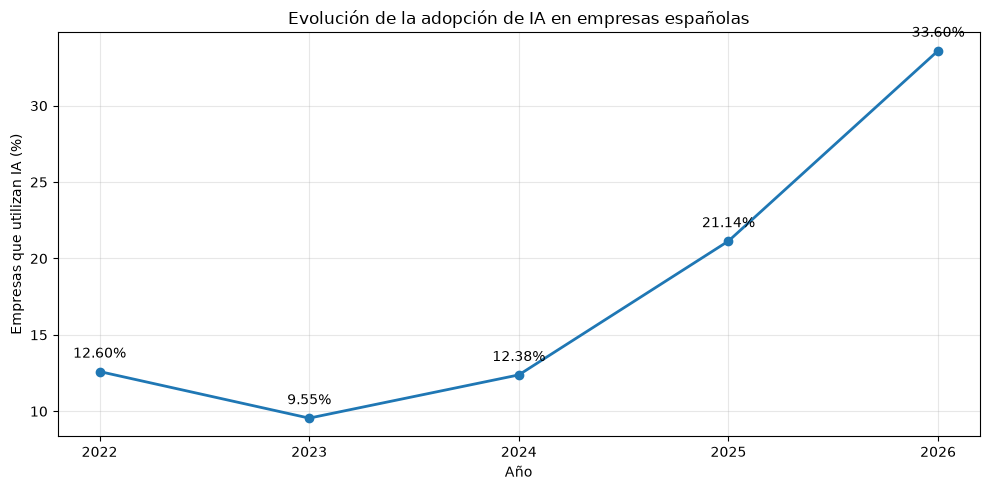

In [ ]:
import matplotlib.pyplot as plt

# ADOPCION DE LA IA EN EMPRESAS ESPAÑOLAS

# Ordenar los datos por año
adopcion_total = adopcion_total.sort_values("year")

plt.figure(figsize=(10, 5))

plt.plot(
    adopcion_total["year"],
    adopcion_total["value_pct"],
    marker="o",
    linewidth=2
)

# Añadir etiquetas de porcentaje
for x, y in zip(
    adopcion_total["year"],
    adopcion_total["value_pct"]
):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("Evolución de la adopción de IA en empresas españolas")
plt.xlabel("Año")
plt.ylabel("Empresas que utilizan IA (%)")
plt.xticks(adopcion_total["year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()